# 02 · Data Preparation

**Brief, section 2:** reshape the data so that every channel is a column holding its daily costs, with the daily sum of all sales as the dependent variable. Then answer four questions:

- What should be taken into account when considering the costs?
- Which channels matter most for sales?
- Which (at least 2) new features should be developed?
- What is the challenge of using channel costs as influencing factors?

The last step builds the **input table for the Meridian MMM** (notebook 03).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from tchibo_mmm import data, features
from tchibo_mmm.plotting import CHANNEL_COLORS, INK_2, MUTED, TOTAL_COLOR, save, thousands, use_style

warnings.filterwarnings("ignore", category=FutureWarning)
use_style()
pd.set_option("display.float_format", "{:,.2f}".format)

raw = data.load_raw()
send_outs = data.catalog_send_out_dates(raw)
PAID = data.PAID_CHANNELS
DIGITAL = [c for c in PAID if c != "Catalog"]

## 1. The wide daily table, in the format the brief asks for

In [2]:
wide = data.build_wide_table(raw)
y = wide["total_sales"]
cost_cols = [c for c in wide.columns if c.startswith("cost_")]
print(f"shape: {wide.shape}  (732 days x 12 cost columns + total_sales)")
print("all-zero cost columns (no cost data):", [c for c in cost_cols if wide[c].sum() == 0])
data.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
wide.to_csv(data.PROCESSED_DIR / "daily_wide.csv")
wide.head()

shape: (732, 13)  (732 days x 12 cost columns + total_sales)
all-zero cost columns (no cost data): ['cost_direct_type_in', 'cost_seo', 'cost_tv', 'cost_direct_referred', 'cost_owned']


channel,cost_sea,cost_catalog,cost_display,cost_affiliate,cost_display_network,cost_social_media,cost_psm,cost_direct_type_in,cost_seo,cost_tv,cost_direct_referred,cost_owned,total_sales
date,,,,,,,,,,,,,
2023-01-01,"40,701.20",0.00,"19,928.03","3,256.78","2,984.09",830.98,"1,181.05",0.00,0.00,0.00,0.00,0.00,"564,772.11"
2023-01-02,"50,381.00",0.00,"20,795.02","3,945.93","3,042.67","21,418.12","1,641.45",0.00,0.00,0.00,0.00,0.00,"800,480.90"
2023-01-03,"50,127.41",0.00,"27,207.31","5,517.75","2,419.68","2,297.15","2,243.85",0.00,0.00,0.00,0.00,0.00,"915,709.86"
2023-01-04,"54,094.85",0.00,"27,422.93","4,391.92","3,144.60","2,231.33","2,304.41",0.00,0.00,0.00,0.00,0.00,"870,530.85"
2023-01-05,"47,865.32",0.00,"27,731.21","6,231.42","3,085.39","2,514.00","2,057.22",0.00,0.00,0.00,0.00,0.00,"856,131.53"


In [3]:
wide[cost_cols].describe(percentiles=[0.5, 0.95]).T[["mean", "50%", "95%", "max"]] \
    .assign(zero_days=(wide[cost_cols] == 0).sum())

,mean,50%,95%,max,zero_days
channel,,,,,
cost_sea,"52,607.59","49,301.84","87,662.16","134,199.35",0
cost_catalog,"52,673.90",0.00,0.00,"1,702,132.97",704
cost_display,"40,717.08","37,818.97","72,463.86","112,222.63",0
cost_affiliate,"6,604.24","5,351.44","13,519.96","62,274.97",0
cost_display_network,"5,591.16","5,080.28","10,597.63","18,134.29",0
cost_social_media,"12,054.47","7,759.85","35,572.03","160,306.78",0
cost_psm,"2,729.94","2,587.85","4,502.73","7,268.44",0
cost_direct_type_in,0.00,0.00,0.00,0.00,732
cost_seo,0.00,0.00,0.00,0.00,732


Five columns (Direct Type-in, SEO, TV, Direct Referred and Owned) are zero on every day, because these channels have no cost data. They stay in the table to answer the brief's question, but they **cannot be used as budget inputs**. Their sales remain part of the target.

## 2. What should be taken into account when considering the costs?

### 2.1 Costs are booked on the day of causation, not on the day of effect

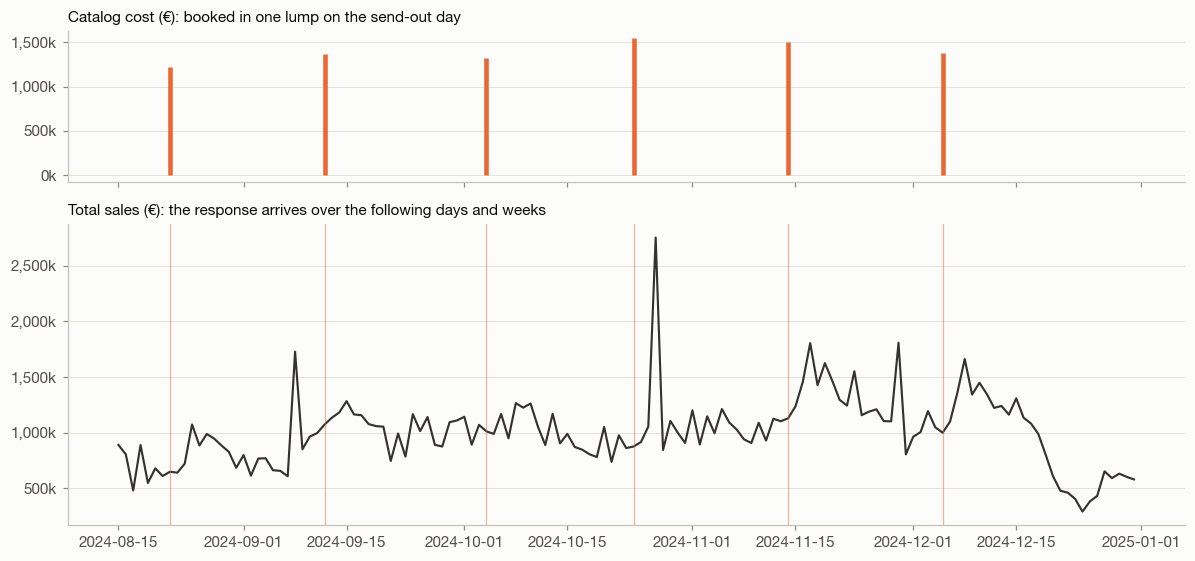

In [4]:
win = slice("2024-08-15", "2024-12-31")
fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
axes[0].vlines(wide.loc[win].index, 0, wide.loc[win, "cost_catalog"], color=CHANNEL_COLORS["Catalog"], lw=3)
axes[0].set_title("Catalog cost (€): booked in one lump on the send-out day", fontsize=10)
thousands(axes[0], unit="k")
axes[1].plot(y.loc[win].index, y.loc[win], color=TOTAL_COLOR, lw=1.4)
for d in send_outs[(send_outs >= "2024-08-15")]:
    axes[1].axvline(d, color=CHANNEL_COLORS["Catalog"], lw=0.8, alpha=0.5)
axes[1].set_title("Total sales (€): the response arrives over the following days and weeks", fontsize=10)
thousands(axes[1], unit="k")
fig.tight_layout()
save(fig, "02_catalog_booking_vs_effect");

### 2.2 Carry-over (adstock): Meridian's decay curves cannot produce a delayed peak

Meridian supports geometric decay (`α^lag`) and binomial decay (`(1 − lag/(L+1))^(1/α − 1)`), as defined in `meridian/model/adstock_hill.py`. **Both are highest at lag 0.** The catalog's measured response, however, peaks 2–3 days after send-out.

The fix is to move the catalog spend to its **in-home date** (k days after send-out). Adstock then models the decay from that date onwards.

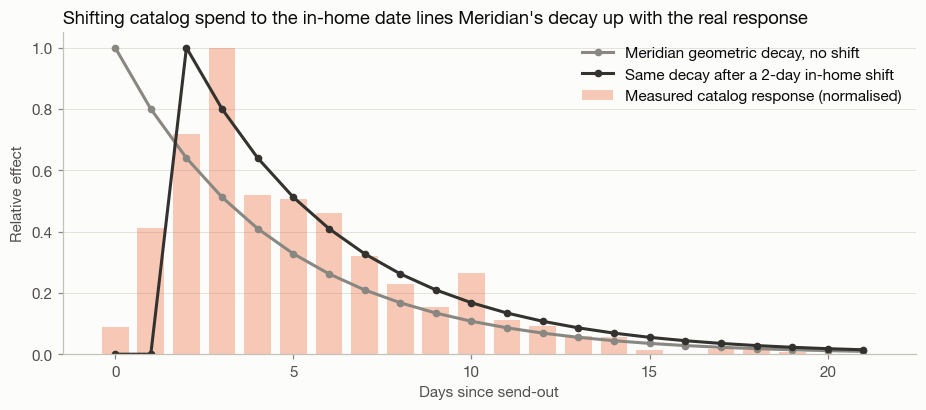

In [5]:
dss = features.days_since_send_out(wide.index, send_outs)
cat_sales = data.sales_by_channel(raw)["Catalog"]
prof = cat_sales.groupby(dss).mean().loc[0:21]
prof = (prof - prof.loc[15:21].mean()).clip(lower=0)
prof /= prof.max()

L = 21
geo = features.geometric_decay_weights(0.8, L)
geo_shift = np.r_[np.zeros(2), geo[:-2]]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(prof.index, prof.values, color=CHANNEL_COLORS["Catalog"], alpha=0.35, width=0.75,
       label="Measured catalog response (normalised)")
ax.plot(range(L + 1), geo, color=MUTED, lw=2, marker="o", ms=4, label="Meridian geometric decay, no shift")
ax.plot(range(L + 1), geo_shift / geo_shift.max(), color=TOTAL_COLOR, lw=2, marker="o", ms=4,
        label="Same decay after a 2-day in-home shift")
ax.set_xlabel("Days since send-out")
ax.set_ylabel("Relative effect")
ax.set_title("Shifting catalog spend to the in-home date lines Meridian's decay up with the real response")
ax.legend(loc="upper right")
save(fig, "02_catalog_adstock_shift");

**Choosing the shift k from the data.** First regress sales on the calendar, seasonality, trend and digital costs. Then correlate the residual with the adstocked catalog spend for each shift k and decay rate α:

In [6]:
ctrl = features.calendar_controls(wide.index).join(features.seasonality_controls(wide.index))
dig_cols = [f"cost_{data.slug(c)}" for c in DIGITAL]
resid = sm.OLS(y, sm.add_constant(ctrl.join(wide[dig_cols]))).fit().resid


def adstock(x, w):
    return np.convolve(np.asarray(x, dtype=float), w)[: len(x)]


rows = []
for k in range(0, 6):
    shifted = features.shift_spend(wide["cost_catalog"], k)
    for decay, fn, grid in [("geometric", features.geometric_decay_weights, [0.5, 0.6, 0.7, 0.8, 0.85, 0.9]),
                            ("binomial", features.binomial_decay_weights, [0.2, 0.3, 0.4, 0.5, 0.6, 0.7])]:
        for a in grid:
            rows.append({"k": k, "decay": decay, "alpha": a,
                         "corr": np.corrcoef(resid, adstock(shifted, fn(a, L)))[0, 1]})
shift_scan = pd.DataFrame(rows)
best = shift_scan.loc[shift_scan.groupby(["k", "decay"])["corr"].idxmax()]
best.pivot(index="k", columns="decay", values="corr").round(3)

decay,binomial,geometric
k,,
0,0.54,0.52
1,0.59,0.58
2,0.59,0.58
3,0.48,0.49
4,0.30,0.33
5,0.21,0.28


**Result:**

- **k = 1–2 days fits best**, with a slow decay (binomial or geometric, α ≈ 0.8).
- **k = 3 is worse,** because it misses the ramp-up on days 1–2.
- **We use k = 2 as the default.** Notebook 03 tests k ∈ {1, 2, 3} on the Meridian hold-out.

### 2.3 Diminishing returns (saturation)

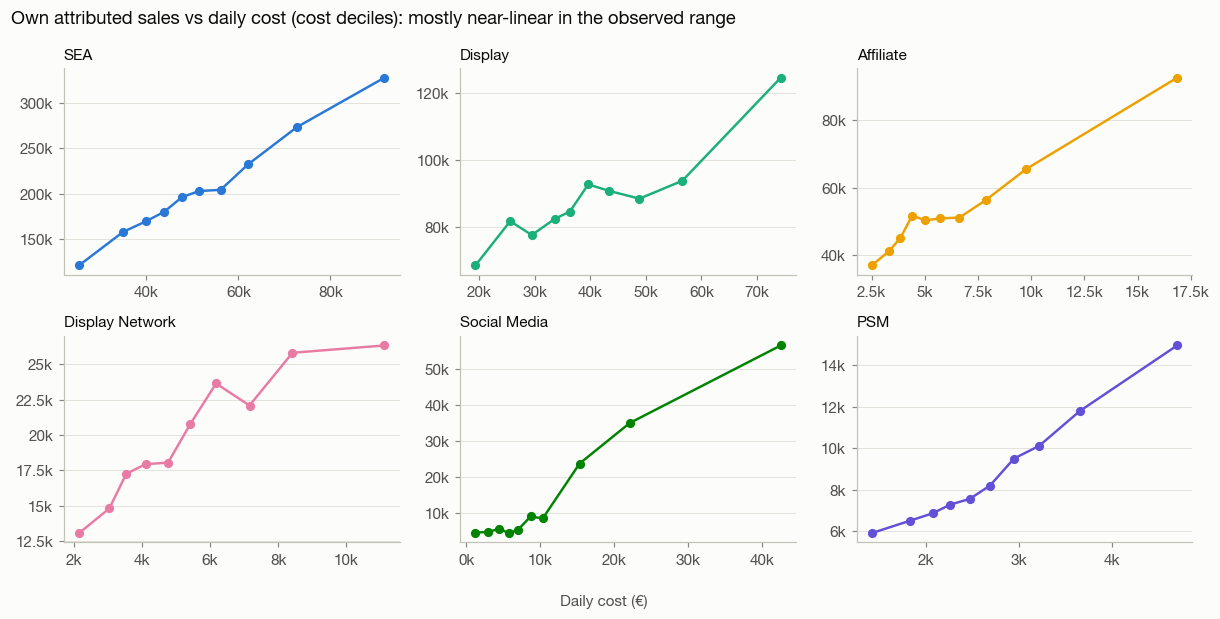

In [7]:
own_sales = data.sales_by_channel(raw)
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for ax, ch in zip(axes.flat, DIGITAL):
    c = wide[f"cost_{data.slug(ch)}"]
    bins = pd.qcut(c, 10, duplicates="drop")
    binned = pd.DataFrame({"cost": c, "sales": own_sales[ch]}).groupby(bins, observed=True).mean()
    ax.plot(binned.cost, binned.sales, color=CHANNEL_COLORS[ch], marker="o", ms=5, lw=1.6)
    ax.set_title(ch, fontsize=10)
    thousands(ax, unit="k"); thousands(ax, axis="x", unit="k")
fig.suptitle("Own attributed sales vs daily cost (cost deciles): mostly near-linear in the observed range",
             x=0.01, ha="left", fontweight="semibold")
fig.supxlabel("Daily cost (€)", color=INK_2, fontsize=10)
fig.tight_layout()
save(fig, "02_saturation");

**What we see:**

- **Within the spend range observed so far, most channels look close to linear** (SEA, Affiliate, PSM).
- **Display Network flattens** at high spend, which is classic diminishing returns.
- **Social Media is S-shaped:** little response at low spend, then a steep rise, which suggests a threshold effect.
- **Saturation therefore cannot be read off the data** for most channels, but it matters as soon as a budget scenario goes beyond today's spend levels.
- **Meridian's Hill curve** can take either form (concave or S-shaped) per channel and learns it from the data and the priors.
- **These are *attributed* sales.** They also move with the season, so the curves are only indicative.

### 2.4 Summary: what to take into account about the costs

| Topic | Observation | How it is handled |
|---|---|---|
| **Booking date** | Cost is booked on the day of causation, e.g. the whole catalog cost on its send-out day | Catalog in-home shift (k = 2) and adstock with `max_lag = 21` |
| **Carry-over** | The effect lasts for days or weeks, about 3 weeks for the catalog | Meridian adstock: geometric, binomial for the catalog |
| **Saturation** | Mostly near-linear in the observed range; Display Network flattens; Social Media is S-shaped | Meridian Hill curve per channel; essential for budget scenarios beyond today's spend |
| **Scale** | Spend ranges from about 2.7 k€/day (PSM) to 1.0–1.7 M€ per catalog send-out | Meridian scales each channel internally |
| **Zero vs missing** | "No cost row" means 0 spend for the catalog, but "not applicable" for unpaid channels | Unpaid channels excluded; catalog off-days set to 0 |
| **Billing model** | SEA is paid per click (r(cost, clicks) = 0.96); Affiliate is a commission on sales (r(cost, own sales) = 0.80) | Interpret their ROI with care; use priors (notebook 03) |
| **Prices change** | CPC and CPM drift, so the same euros do not buy the same reach every month | Limitation; impressions are used in a sensitivity variant only |
| **Forecasting** | Spend for the days ahead must be known in advance, i.e. the *planned* budget | Spend is the media input, so the model runs on a budget plan |

## 3. New features (the brief requires at least 2)

In [8]:
ctrl.head(8)

,dow_tue,dow_wed,dow_thu,dow_fri,dow_sat,dow_sun,holiday,christmas,half_day,black_week,sin_1,cos_1,sin_2,cos_2,trend
date,,,,,,,,,,,,,,,
2023-01-01,0.00,0.00,0.00,0.00,0.00,1.00,1.00,0.00,0.00,0.00,0.02,1.00,0.03,1.00,0.00
2023-01-02,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.03,1.00,0.07,1.00,0.00
2023-01-03,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.05,1.00,0.10,0.99,0.01
2023-01-04,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.07,1.00,0.14,0.99,0.01
2023-01-05,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.09,1.00,0.17,0.99,0.01
2023-01-06,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.10,0.99,0.20,0.98,0.01
2023-01-07,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.12,0.99,0.24,0.97,0.02
2023-01-08,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.14,0.99,0.27,0.96,0.02


| # | Feature | Columns | Why |
|---|---|---|---|
| 1 | **Catalog in-home spend** | `catalog_spend` shifted by k = 2 days | Aligns the catalog lump with its real effect; feeds Meridian's adstock |
| 2 | **Calendar controls** | weekday dummies (Monday is the reference), `holiday` (German public holidays), `christmas` (20–31 Dec), `half_day` (24 and 31 Dec, the half-day holidays of Google's German holiday calendar), `black_week` (Black Friday to Cyber Monday) | Sunday and Tuesday peaks, the Christmas dip (deepest on Christmas Eve and New Year's Eve) and Black Friday |
| 3 | **Seasonality and trend** | yearly Fourier terms `sin_k`, `cos_k` (k = 1, 2); `trend` (years since start) | Q4 seasonality and the +21 % year-on-year growth. Used as controls so the baseline can extend into a future hold-out |

How much each group adds (in-sample adjusted R² of a plain OLS; proper out-of-sample validation follows in notebooks 03 and 04):

In [9]:
def adj_r2(X):
    return sm.OLS(y, sm.add_constant(X)).fit().rsquared_adj


cat_inhome = pd.Series(adstock(features.shift_spend(wide["cost_catalog"], 2), features.geometric_decay_weights(0.8, L)),
                       index=wide.index, name="catalog_inhome_adstock")
cal = features.calendar_controls(wide.index)
seas = features.seasonality_controls(wide.index)
ladder = pd.Series({
    "raw costs (7 channels)": adj_r2(wide[dig_cols + ["cost_catalog"]]),
    "+ calendar controls": adj_r2(wide[dig_cols + ["cost_catalog"]].join(cal)),
    "+ seasonality & trend": adj_r2(wide[dig_cols + ["cost_catalog"]].join(cal).join(seas)),
    "catalog raw -> in-home adstock": adj_r2(wide[dig_cols].join(cal).join(seas).join(cat_inhome)),
}, name="adjusted R²")
ladder.round(3)

raw costs (7 channels)           0.74
+ calendar controls              0.76
+ seasonality & trend            0.83
catalog raw -> in-home adstock   0.90
Name: adjusted R², dtype: float64

## 4. Which channels matter most for sales?

This is a first answer from a transparent regression. Notebook 03 gives Meridian's posterior contributions and ROI as the final answer.

- **Model:** OLS of total sales on the (adstocked) channel costs and all controls, with Newey-West standard errors to allow for autocorrelated residuals.
- **Coefficients:** standardised, i.e. the sales effect of a 1-standard-deviation change in spend.
- **Contribution share:** coefficient × average input ÷ average sales.

In [10]:
X_imp = wide[dig_cols].join(cat_inhome).join(cal).join(seas)
X_imp.columns = [c.replace("cost_", "") for c in X_imp.columns]
ols = sm.OLS(y, sm.add_constant(X_imp)).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
media = [data.slug(c) for c in DIGITAL] + ["catalog_inhome_adstock"]
names = dict(zip(media, DIGITAL + ["Catalog"]))
sd = X_imp[media].std()
importance = pd.DataFrame({
    "std_effect": ols.params[media] * sd,
    "ci_low": ols.conf_int().loc[media, 0] * sd,
    "ci_high": ols.conf_int().loc[media, 1] * sd,
    "p_value": ols.pvalues[media],
    "contribution_share": ols.params[media] * X_imp[media].mean() / y.mean(),
}).rename(index=names).sort_values("std_effect")
print(f"OLS R² = {ols.rsquared:.3f}")
importance.style.format({"std_effect": "{:,.0f}", "ci_low": "{:,.0f}", "ci_high": "{:,.0f}",
                         "p_value": "{:.3f}", "contribution_share": "{:.1%}"})

OLS R² = 0.906


,std_effect,ci_low,ci_high,p_value,contribution_share
Social Media,"-4,854","-16,275","6,567",0.405,-0.5%
Display Network,-644,"-12,695","11,408",0.917,-0.2%
Display,865,"-12,639","14,370",0.900,0.3%
PSM,"9,465","-6,802","25,733",0.254,3.5%
Catalog,"81,786","71,111","92,462",0.000,7.3%
SEA,"89,350","64,335","114,365",0.000,31.7%
Affiliate,"148,949","132,096","165,801",0.000,25.3%


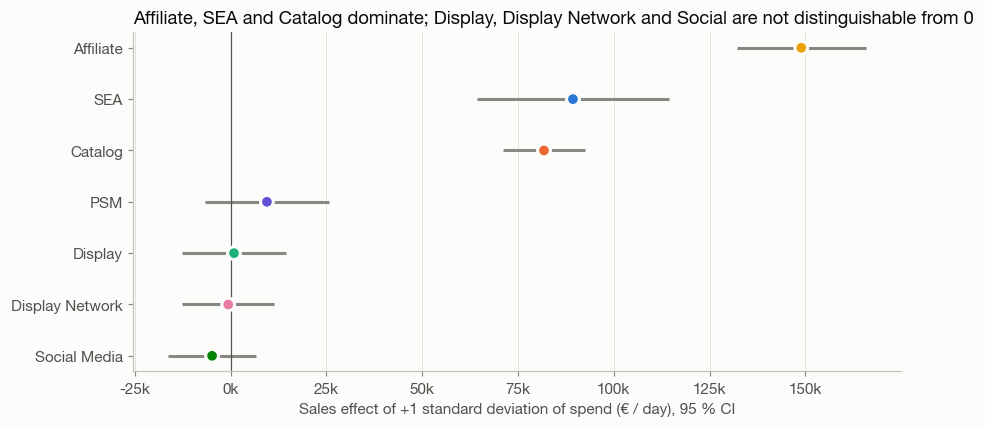

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
pos = np.arange(len(importance))
ax.hlines(pos, importance.ci_low, importance.ci_high, color=MUTED, lw=2)
ax.scatter(importance.std_effect, pos, s=70, zorder=3, color=[CHANNEL_COLORS[c] for c in importance.index],
           edgecolor="#fcfcfb", linewidth=2)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_yticks(pos, importance.index)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
thousands(ax, axis="x", unit="k")
ax.set_xlabel("Sales effect of +1 standard deviation of spend (€ / day), 95 % CI")
ax.set_title("Affiliate, SEA and Catalog dominate; Display, Display Network and Social are not distinguishable from 0")
save(fig, "02_channel_importance");

**Reading the result (preliminary):**

- **Affiliate, SEA and Catalog** are the only clearly significant channels (p < 0.001). Together they explain most of the marketing-driven sales.
- **Affiliate's effect is almost certainly overstated.** Its cost is a commission paid on sales, so high-sales days create high Affiliate cost, and not only the other way round. The same holds, to a lesser degree, for SEA, which is paid per click.
- **Catalog's contribution share (~7 %) is likely understated.** Catalog is sent out on a regular schedule, so the seasonality and trend controls can absorb part of its effect. Its halo on other channels (notebook 01) points to a larger true effect.
- **Display, Display Network, Social Media and PSM** cannot be told apart from zero in this regression.

Meridian (notebook 03) re-estimates these effects with priors and saturation. Plausible ROIs, especially for Affiliate and Catalog, are an explicit check there.

## 5. What is the challenge of using channel costs as influencing factors?

In [12]:
V = sm.add_constant(wide[dig_cols])
vif = pd.Series({c.replace("cost_", ""): variance_inflation_factor(V.values, i)
                 for i, c in enumerate(V.columns) if c != "const"}, name="VIF")
monthly_spend_corr = wide[dig_cols].sum(axis=1).resample("ME").sum().corr(y.resample("ME").sum())
print(f"correlation of monthly digital spend with monthly sales: {monthly_spend_corr:.2f}")
vif.round(2)

correlation of monthly digital spend with monthly sales: 0.92


sea               2.41
display           1.85
affiliate         1.41
display_network   1.67
social_media      1.44
psm               1.50
Name: VIF, dtype: float64

1. **Reverse causality (endogeneity), the main challenge.**
   - Budgets are planned around *expected* demand: monthly digital spend and monthly sales move together.
   - Performance channels are billed on demand: SEA per click (r = 0.96 with clicks) and Affiliate per sale (r = 0.80 with its own sales).
   - So part of the cost–sales correlation runs from sales to cost, and naive ROI estimates for SEA and Affiliate are inflated.
2. **Correlated inputs.**
   - Digital costs correlate at r = 0.2–0.6 and rise together in Q4.
   - The VIFs (≤ 2.4) show only moderate multicollinearity, but the effects of individual channels still have wide intervals (see Display and Social above).
   - Meridian's priors stabilise these estimates.
3. **Timing and shape.**
   - Costs are booked on the day of causation, while the effects are delayed (catalog), carry over (adstock) and saturate (Hill).
   - A linear same-day model therefore misreads the catalog completely (r ≈ 0).
4. **Little independent variation.**
   - Spend is never switched off in an experiment-like way; September 2023 without a catalog is the only natural experiment.
   - Effects are therefore weakly identified. Lift tests or geo experiments would calibrate the priors.
5. **Attribution vs incrementality.**
   - Channel-attributed sales (and ROAS) are not causal. The catalog's halo on SEO and Direct Type-in shows this.
   - The model therefore targets **total** sales.
6. **Forecast-time availability.**
   - Future costs must be known in advance, i.e. a planned budget.
   - For SEA and Affiliate the realised cost depends on demand, so the plan is only an upper limit.

## 6. Meridian input table

| Meridian role | Columns |
|---|---|
| `time` | daily date, `YYYY-MM-DD` |
| KPI (`kpi_type="revenue"`) | `total_sales` |
| media = media spend | `sea_spend`, `catalog_spend` (shifted to the in-home date), `display_spend`, `affiliate_spend`, `display_network_spend`, `social_media_spend`, `psm_spend` |
| controls | weekday dummies, `holiday`, `christmas`, `half_day`, `black_week`, `sin_1`, `cos_1`, `sin_2`, `cos_2`, `trend` |

In [13]:
table = features.build_meridian_table(wide, catalog_shift=features.DEFAULT_CATALOG_SHIFT)
assert table.notna().all().all() and len(table) == len(wide)
assert (pd.to_datetime(table.time).diff().dropna() == pd.Timedelta(days=1)).all()
assert np.isclose(table.catalog_spend.sum() + wide.cost_catalog.iloc[-features.DEFAULT_CATALOG_SHIFT:].sum(),
                  wide.cost_catalog.sum())
print("spend columns:", features.spend_columns())
print("controls:", features.control_columns(table))
table.to_csv(data.PROCESSED_DIR / "meridian_input.csv", index=False)
table.head()

spend columns: ['sea_spend', 'catalog_spend', 'display_spend', 'affiliate_spend', 'display_network_spend', 'social_media_spend', 'psm_spend']
controls: ['dow_tue', 'dow_wed', 'dow_thu', 'dow_fri', 'dow_sat', 'dow_sun', 'holiday', 'christmas', 'half_day', 'black_week', 'sin_1', 'cos_1', 'sin_2', 'cos_2', 'trend']


,time,total_sales,sea_spend,catalog_spend,display_spend,affiliate_spend,display_network_spend,social_media_spend,psm_spend,dow_tue,...,dow_sun,holiday,christmas,half_day,black_week,sin_1,cos_1,sin_2,cos_2,trend
0,2023-01-01,"564,772.11","40,701.20",0.00,"19,928.03","3,256.78","2,984.09",830.98,"1,181.05",0.00,...,1.00,1.00,0.00,0.00,0.00,0.02,1.00,0.03,1.00,0.00
1,2023-01-02,"800,480.90","50,381.00",0.00,"20,795.02","3,945.93","3,042.67","21,418.12","1,641.45",0.00,...,0.00,0.00,0.00,0.00,0.00,0.03,1.00,0.07,1.00,0.00
2,2023-01-03,"915,709.86","50,127.41",0.00,"27,207.31","5,517.75","2,419.68","2,297.15","2,243.85",1.00,...,0.00,0.00,0.00,0.00,0.00,0.05,1.00,0.10,0.99,0.01
3,2023-01-04,"870,530.85","54,094.85",0.00,"27,422.93","4,391.92","3,144.60","2,231.33","2,304.41",0.00,...,0.00,0.00,0.00,0.00,0.00,0.07,1.00,0.14,0.99,0.01
4,2023-01-05,"856,131.53","47,865.32",0.00,"27,731.21","6,231.42","3,085.39","2,514.00","2,057.22",0.00,...,0.00,0.00,0.00,0.00,0.00,0.09,1.00,0.17,0.99,0.01
